1. criar e ler um arquivo

In [ ]:
with open("arquivo.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write("primeira linha\n")
    arquivo.write("segunda linha\n")
    arquivo.write("terceira linha")

with open("arquivo.txt", "r") as arquivo:
    texto = arquivo.read()

print(texto)

primeira linha
segunda linha
terceira linha


2. contar linhas

In [5]:
with open("arquivo.txt", "r", encoding="utf-8") as arquivo:
    total_linhas = sum(1 for linha in arquivo)

print(f'total de linhas: {total_linhas}')

total de linhas: 3


3. contar palavras

In [6]:
with open("arquivo.txt", "r", encoding="utf-8") as arquivo:
    texto = arquivo.read()

palavras = texto.split()
total_palavras = len(palavras)

print(f'total de palavras: {total_palavras}')

total de palavras: 6


4. somar números

In [14]:
with open('numeros.txt', 'w', encoding='utf-8') as f:
    for i in range(1, 10):
        f.write(f'{i}\n')

soma = 0
quantidade = 0

with open('numeros.txt', 'r', encoding='utf-8') as f:
    for linha in f:
        print(linha, end='')
        numero = float(linha)
        soma += numero 
        quantidade += 1

media = soma / quantidade 

print(f'\nsoma = {soma}\tmédia = {media}')


1
2
3
4
5
6
7
8
9

soma = 45.0	média = 5.0


5. filtrar linhas

In [42]:
texto = [
    'Python é legal!\n',
    'Trabalhadores do mundo, uni-vos!\n',
    'O Grêmio será rebaixado.\n',
    'A linguagem de programação Python é fácil de aprender.'
]

palavra_busca = "Python"

with open('entrada.txt', 'w', encoding='utf-8') as f1:
    f1.writelines(texto)

with open('entrada.txt', 'r') as f1, open('resultado.txt', 'w', encoding='utf-8') as f2:
    linhas_filtradas = [linha for linha in f1 if palavra_busca.lower() in linha.lower()]
    f2.writelines(linhas_filtradas)

with open('resultado.txt', 'r') as f2:
    texto = f2.read()

print(texto)

Python é legal!
A linguagem de programação Python é fácil de aprender.


6. acrescentar informações

In [22]:
novo_nome = input('digite novo nome: ')

with open('nomes.txt', 'a', encoding='utf-8') as f:
    f.write(f'{novo_nome}\n')

print(f'o nome {novo_nome} foi adicionado com sucesso ao arquivo.')

o nome pedro foi adicionado com sucesso ao arquivo.


7. processar um arquivo CSV

In [45]:
import csv 

dados = [
    ["Ana", 8.5],
    ["Bruno", 7.0],
    ["Carlos", 9.2],
    ["Diana", 6.8]
]

with open('notas.csv', 'w', encoding='utf-8', newline='') as f:
    escritor = csv.writer(f)
    escritor.writerow(['Nome', 'Nota'])
    escritor.writerows(dados)

soma = 0
quantidade = 0

with open('notas.csv', 'r', encoding='utf-8', newline='') as f:
    leitor = csv.DictReader(f)

    for linha in leitor:
        nome = linha['Nome']
        nota = float(linha['Nota'])
        soma += nota 
        quantidade += 1

media = soma / quantidade
print(f'A média das notas é {media}')

A média das notas é 7.875


8. criar e ler um arquivo binário

In [67]:
inteiros = bytes([i for i in range(4)])

with open("inteiros.bin", "wb") as f:
    f.write(inteiros)

with open("inteiros.bin", "rb") as f:
    inteiros2 = f.read()

print(inteiros2)
print(list(inteiros2))

b'\x00\x01\x02\x03'
[0, 1, 2, 3]


9. copiar um arquivo binário em blocos

In [68]:
try:
    with open("origem.bin", "rb") as origem:
        with open("copia.bin", "wb") as destino:

            while True:
                bloco = origem.read(1024)

                if not bloco:
                    break
                destino.write(bloco)
except FileNotFoundError:
    print("Arquivo não encontrado.")

Arquivo não encontrado.


10. serializar e recuperar um dicionário

In [66]:
import pickle 

dados = {
    "nome": "Lucas",
    "idade": 23,
    "notas": [9.0, 9.5]
}

with open("dados.pkl", "wb") as f:
    pickle.dump(dados, f)

with open("dados.pkl", "rb") as f:
    dados2 = pickle.load(f)

print(dados2)

{'nome': 'Lucas', 'idade': 23, 'notas': [9.0, 9.5]}


11. exercício combinado desafiador

Título: Previsão de precipitação pluviométrica (em mm) em Porto Alegre - RS
Dimensões: 20 linhas x 20 colunas
Latitude: de -28.000° a -32.500°
Longitude: de -56.000° a -50.000°
Precipatação mínima: 4.0 mm
Precipatação máxima: 50.9 mm


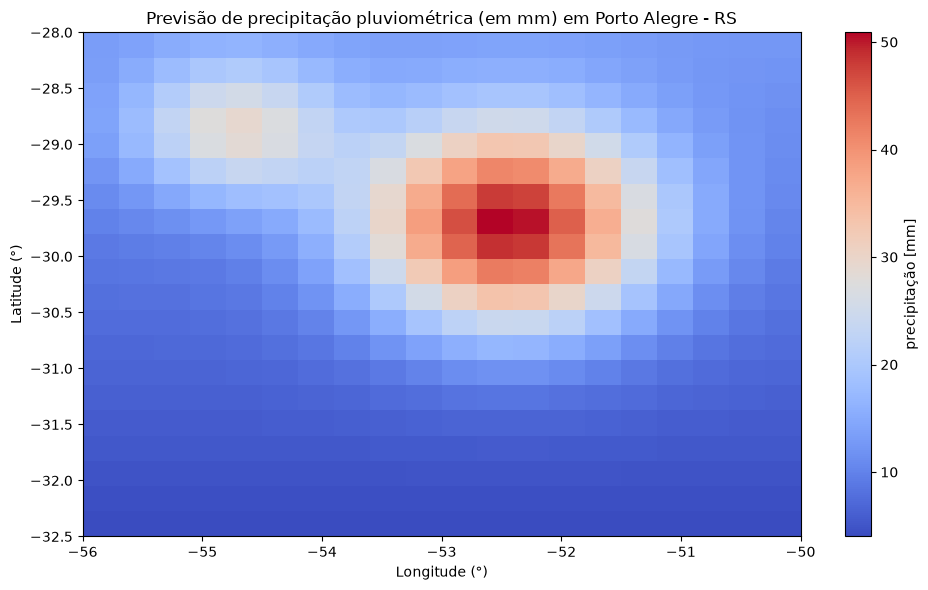

In [6]:
import re
import numpy as np
import matplotlib.pyplot as plt

# leitura do cabecalho
with open("previsão_pluviométrica_poa.txt", "r", ) as f:
    titulo = f.readline().lstrip('# ').strip()
    dimensoes = f.readline().strip()
    f.readline() # terceira linha delimitacao geografica
    latitude = f.readline().strip()
    longitude = f.readline().strip()

    # extracao das dimensoes
    m, n = map(int, re.findall(r'\d+', dimensoes))

    # extracao das coordenadas geograficas
    lat_inicio, lat_fim = map(float, re.findall(r'-?\d+\.\d+', latitude))
    lon_inicio, lon_fim = map(float, re.findall(r'-?\d+\.\d+', longitude))

    # leitura da matriz de precipitacao
    linhas = []

    for _ in range(m):
        linha = f.readline().strip()
        linha = linha.rstrip('\\')

        valores = [float(x) for x in linha.split('&')]
        linhas.append(valores)

P = np.array(linhas)

# exibicao das informacoes do cabecalho
print(f'Título: {titulo}')
print(f'Dimensões: {m} linhas x {n} colunas')
print(f'Latitude: de {lat_inicio:.3f}° a {lat_fim:.3f}°')
print(f'Longitude: de {lon_inicio:.3f}° a {lon_fim:.3f}°')

# calculo dos valores minimo e maximo
print(f'Precipatação mínima: {P.min():.1f} mm')
print(f'Precipatação máxima: {P.max():.1f} mm')

# construcao do grafico
fig, ax = plt.subplots(figsize=(10, 6))

imagem = ax.imshow(
    P,
    cmap='coolwarm',
    origin='upper',
    extent=[lon_inicio, lon_fim, lat_fim, lat_inicio],
    aspect='auto'
)

ax.set_title(titulo)
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")

barra = fig.colorbar(imagem, ax=ax)
barra.set_label("precipitação [mm]")

fig.tight_layout()

# salva o grafico
fig.savefig(
    "previsão_pluviométrica_poa.png",
    dpi=300,
    format="png"
)

plt.show()